# Big Data Integration with Alaska: complete service lab
Run with Docker Compose as described in README.md. Every required engine is enabled;
missing prerequisites fail visibly. The Compose deployment uses two Spark worker
containers on one physical host. Results do not establish physical multi-node speedup.
The HTTP event service replays real Alaska titles at ingestion time; it is a controlled
streaming experiment, not current commercial product activity.

The default scope is the complete monitor domain. Set ALASKA_DOMAINS=camera,monitor,notebook
to ingest all three domains for a larger benchmark. Ground truth is used for evaluation only.


In [1]:
from pathlib import Path
import os, json, re, tarfile, hashlib, time, platform, importlib.metadata
import itertools, statistics, unicodedata
import numpy as np
import pandas as pd
import dask.dataframe as dd
import sqlalchemy as sa
import requests
import matplotlib.pyplot as plt
import seaborn as sns
DATA=Path('lab_data'); RESULTS=Path('lab_results')
DATA.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
RUN_SPARK=True
RUN_MONGO=True
RUN_STREAM=True
status={'pandas':'pending','dask':'pending','sql':'pending','spark':'not run','mongo':'not run','kafka':'not run'}
versions={p:importlib.metadata.version(p) for p in ['pandas','dask','sqlalchemy','matplotlib','seaborn']}
print(platform.platform(), versions)
from lab_extensions import mongo_integration, spark_session, stream_replay
topology = {}; stream_metrics = {}; dedup_summary = {}


Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.35 {'pandas': '2.2.3', 'dask': '2025.2.0', 'sqlalchemy': '2.0.39', 'matplotlib': '3.10.0', 'seaborn': '0.13.2'}


## 1 Ingest heterogeneous JSON and retain provenance
The official repository distributes monitor.tar.gz. Each specification is a JSON object under a website directory. Ground truth uses `website//filename_without_extension`. The loader reads regular JSON members directly from the archive and extracts only CSV labels after checking their destination paths. This avoids thousands of small file writes. The SHA256 digest identifies the downloaded archive; it is a provenance fingerprint, not an independently verified checksum.

In [2]:
domains = os.getenv('ALASKA_DOMAINS', 'monitor').split(',')
if not set(domains) <= {'camera', 'monitor', 'notebook'}:
    raise ValueError('ALASKA_DOMAINS must contain official domain names')
archives = []
for domain in domains:
    archive = DATA / (domain + '.tar.gz')
    if not archive.exists():
        response = requests.get('https://raw.githubusercontent.com/merialdo/research.alaska/main/' + domain + '.tar.gz', timeout=180)
        response.raise_for_status()
        archive.write_bytes(response.content)
    archives.append(archive)
archive_hashes = {a.name: hashlib.sha256(a.read_bytes()).hexdigest() for a in archives}
digest = archive_hashes
root=DATA/'monitor'; root.mkdir(exist_ok=True)
records=[]; attrs=[]; bad=[]
for archive in archives:
    with tarfile.open(archive) as tf:
        for member in tf:
            if not member.isfile(): continue
            member_path=Path(member.name)
            if member_path.suffix.lower() not in {'.json','.csv'}: continue
            if member_path.is_absolute() or '..' in member_path.parts: raise ValueError('Unsafe archive path')
            if member_path.suffix.lower()=='.csv':
                target=(root/member.name).resolve()
                if not target.is_relative_to(root.resolve()): raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True,exist_ok=True)
                target.write_bytes(tf.extractfile(member).read())
                continue
            try:
                obj=json.loads(tf.extractfile(member).read().decode('utf-8'))
                if not isinstance(obj,dict): raise ValueError('Expected specification object')
                source=member_path.parent.name; spec_id=f'{source}//{member_path.stem}'
                records.append({'spec_id':spec_id,'source':source,'raw':obj})
                attrs.extend({'spec_id':spec_id,'source':source,'attribute':k,'value':str(v)} for k,v in obj.items())
            except (ValueError,UnicodeError) as exc: bad.append({'file':member.name,'error':str(exc)})
raw=pd.DataFrame(records); long=pd.DataFrame(attrs)
assert len(raw)>0 and raw.spec_id.is_unique
pd.DataFrame(bad).to_csv(RESULTS/'quarantine.csv',index=False)
print({'records':len(raw),'sources':raw.source.nunique(),'attribute_names':long.attribute.nunique(),'quarantined':len(bad),'sha256':digest})
print('CSV files:',[str(p) for p in root.rglob('*.csv')])

{'records': 16662, 'sources': 26, 'attribute_names': 1688, 'quarantined': 0, 'sha256': {'monitor.tar.gz': '9084b8998d5afa283865dfcf8e1f3cc4137f6befbe431903a4d83df4b3f7b45d'}}
CSV files: ['lab_data/monitor/monitor/monitor_ground_truths/monitor_entity_resolution_gt.csv', 'lab_data/monitor/monitor/monitor_ground_truths/monitor_schema_matching_gt.csv']


## 2 Schema matching and cleaning
This manually specified baseline maps a small set of attribute aliases; it does not learn mappings from evaluation labels. Raw fields are preserved. Conflicting mapped values are counted and a deterministic first nonempty value is selected. Missing brand/model stays missing. Screen size is converted from explicit cm or inch values; unitless numbers are rejected. Titles are unstructured text and model extraction is a fallible fallback.

In [3]:
def norm(x):
    if x is None or (isinstance(x,float) and pd.isna(x)): return ''
    return re.sub(r'\s+',' ',unicodedata.normalize('NFKC',str(x)).casefold()).strip()
aliases={'brand':{'brand','manufacturer'},'model':{'model','model number','manufacturer part number'},
         'screen_inches':{'screen size','screen size diagonal','display size'}}
def inches(v):
    v=norm(v)
    m=re.search(r"(\d+(?:\.\d+)?)\s*(cm|inches|inch|in\b|[\"']+)",v)
    if not m: return np.nan
    x=float(m.group(1)); x=x/2.54 if m.group(2)=='cm' else x
    return x if 5<=x<=100 else np.nan
def canonical(row):
    obj={norm(k):v for k,v in row['raw'].items()}; out={k:row[k] for k in ['spec_id','source']}
    out['title']=str(obj.get('<page title>','')); conflicts=0
    for target,names in aliases.items():
        values=[norm(obj[k]) for k in sorted(names) if k in obj and norm(obj[k]) not in {'','n/a','unknown','-'}]
        conflicts+=int(len(set(values))>1)
        out[target]=values[0] if values else ''
    out['screen_inches']=inches(out['screen_inches'])
    if not out['model']:
        tokens=re.findall(r'\b[a-z0-9-]+\b',norm(out['title']))
        out['model']=next((t for t in tokens if re.search('[a-z]',t) and re.search('[0-9]',t)), '')
    out['brand']=re.sub(r'[^a-z0-9]','',out['brand'])
    out['model']=re.sub(r'[^a-z0-9]','',out['model'])
    out['conflicts']=conflicts
    return out
clean=pd.DataFrame(canonical(row) for row in records)
clean['entity_key']=np.where(clean.brand.ne('') & clean.model.ne(''),clean.brand+'|'+clean.model,None)
# Specification duplicates and entity duplicates are different concepts.
assert clean.spec_id.is_unique
clean.to_csv(DATA/'canonical.csv',index=False)
quality={'records':len(clean),'sources':clean.source.nunique(),
 'missing_brand':int(clean.brand.eq('').sum()),'missing_model':int(clean.model.eq('').sum()),
 'missing_screen':int(clean.screen_inches.isna().sum()),'conflicting_records':int(clean.conflicts.gt(0).sum())}
status['pandas']='completed'; print(quality)
def dask_clean_partition(frame):
    frame = frame.copy()
    frame['brand'] = frame['brand'].map(lambda v: re.sub(r'[^a-z0-9]', '', norm(v)))
    frame['model'] = frame['model'].map(lambda v: re.sub(r'[^a-z0-9]', '', norm(v)))
    frame['screen_inches'] = pd.to_numeric(frame['screen_inches'], errors='coerce')
    frame['screen_inches'] = frame['screen_inches'].where(frame['screen_inches'].between(5, 100))
    return frame

distributed = dd.read_csv(str(DATA/'canonical.csv'), blocksize='256KiB',
    keep_default_na=False, dtype={'brand':'object','model':'object','entity_key':'object', 'screen_inches':'object'})
meta = distributed._meta.copy()
meta['screen_inches'] = pd.Series(dtype='float64')
dask_cleaned = distributed.map_partitions(dask_clean_partition, meta=meta).drop_duplicates(subset=['spec_id']).compute()
pd.testing.assert_frame_equal(clean[['spec_id','brand','model','screen_inches']].sort_values('spec_id').reset_index(drop=True),
    dask_cleaned[['spec_id','brand','model','screen_inches']].sort_values('spec_id').reset_index(drop=True), check_dtype=False)
# A deliberately duplicated input demonstrates duplicate removal without claiming
# the original archive contains those injected duplicate listings.
probe = pd.concat([clean, clean.head(5)], ignore_index=True)
probe_dd = dd.from_pandas(probe, npartitions=4).drop_duplicates(subset=['spec_id']).compute()
assert len(probe_dd) == len(clean)
dedup_summary['duplicate_probe_removed'] = len(probe) - len(probe_dd)
dask_cleaned.to_parquet(DATA/'dask_cleaned.parquet', index=False)


{'records': 16662, 'sources': 26, 'missing_brand': 8944, 'missing_model': 813, 'missing_screen': 8671, 'conflicting_records': 152}


## 3 Equivalent Pandas and Dask benchmarks
Both engines read the same canonical CSV, select nonmissing screen values, and aggregate count and mean by source. Every trial materializes its result. One warm-up and three trials exclude JSON parsing and canonicalization; filesystem caching remains uncontrolled. These measurements concern this local workload only. Larger-than-memory ingestion should write partitioned Parquet incrementally instead of constructing all records in RAM.

In [4]:
def pandas_job():
    x=pd.read_csv(DATA/'canonical.csv')
    return x.dropna(subset=['screen_inches']).groupby('source').screen_inches.agg(['count','mean']).sort_index()
def dask_job():
    x=dd.read_csv(str(DATA/'canonical.csv'),blocksize='256KiB',dtype={'brand':'object','model':'object','entity_key':'object'})
    return x.dropna(subset=['screen_inches']).groupby('source').screen_inches.agg(['count','mean']).compute().sort_index()
timings=[]
for name,fn in [('Pandas',pandas_job),('Dask',dask_job)]:
    fn()
    for trial in range(3):
        t=time.perf_counter(); result=fn(); elapsed=time.perf_counter()-t
        timings.append({'engine':name,'trial':trial+1,'seconds':elapsed})
pd.testing.assert_frame_equal(pandas_job(),dask_job(),check_dtype=False,check_index_type=False,rtol=1e-9)
timings=pd.DataFrame(timings); timings.to_csv(RESULTS/'timings.csv',index=False)
status['dask']='completed'; print(timings.groupby('engine').seconds.agg(['median','min','max']))

          median       min       max
engine                              
Dask    0.219605  0.212068  0.219648
Pandas  0.049366  0.046219  0.052739


## 4 SQL, CSV, JSON, and MongoDB integration
SQLAlchemy retrieves a staged source dimension from SQLite. PyMongo upserts and retrieves original documents in batches. Cardinality and coverage assertions verify the unified merge. Services are required and failures stop execution.


In [5]:
engine=sa.create_engine('sqlite:///'+str((DATA/'lab.sqlite').resolve()))
source_meta=clean.groupby('source').size().rename('source_record_count').reset_index()
source_meta.to_sql('sources',engine,if_exists='replace',index=False)
with engine.connect() as con: sql_meta=pd.read_sql(sa.text('SELECT source, source_record_count FROM sources'),con)
csv=pd.read_csv(DATA/'canonical.csv',keep_default_na=False)
unified=csv.merge(sql_meta,on='source',how='left',validate='many_to_one')
assert len(unified)==len(clean) and unified.source_record_count.notna().all()
status['sql']='completed'; print(unified[['spec_id','source_record_count']].head())
unified = mongo_integration(records, unified)
status['mongo'] = 'completed'
unified.to_json(RESULTS/'unified.jsonl',orient='records',lines=True)

                 spec_id  source_record_count
0  www.shopmania.com//56                  108
1  www.shopmania.com//61                  108
2  www.shopmania.com//80                  108
3  www.shopmania.com//62                  108
4  www.shopmania.com//34                  108


## 5 Entity resolution and labeled evaluation
Match only exact normalized brand and model within a block, across different websites. Empty keys never match. No fuzzy threshold is tuned on test labels. Evaluate on the labeled subset, treating labels as complete only within that subset. Ground truth is not joined into features. Unlabeled records are excluded from scoring; the score cannot establish accuracy across all Alaska records. Candidate recall is measured against all cross-source true pairs, so blocking misses count as false negatives.

In [6]:
truth_files=[]
for p in root.rglob('*.csv'):
    header=pd.read_csv(p,nrows=0).columns
    if {'entity_id','spec_id'}<=set(header): truth_files.append(p)
if not truth_files: raise FileNotFoundError('Entity ground truth CSV not found')
truth=pd.concat([pd.read_csv(p,dtype=str)[['entity_id','spec_id']] for p in truth_files]).drop_duplicates()
truth['spec_id']=truth.spec_id.str.replace('\\','/',regex=False).str.replace(r'\.json$','',regex=True)
memberships=truth.groupby('spec_id').entity_id.nunique()
ambiguous_ids=memberships[memberships>1].index
truth=truth[~truth.spec_id.isin(ambiguous_ids)]
print('Excluded multi-entity specification IDs:',len(ambiguous_ids))
labeled=clean.merge(truth,on='spec_id',validate='one_to_one')
assert len(labeled)>0, 'Check archive identifier layout'
def pairs(frame,key):
    out=set()
    for _,g in frame.dropna(subset=[key]).groupby(key):
        for a,b in itertools.combinations(g[['spec_id','source']].itertuples(index=False,name=None),2):
            if a[1]!=b[1]: out.add(tuple(sorted((a[0],b[0]))))
    return out
pred=pairs(labeled,'entity_key'); actual=pairs(labeled,'entity_id')
tp=len(pred & actual); fp=len(pred-actual); fn=len(actual-pred)
precision=tp/(tp+fp) if tp+fp else 0.; recall=tp/(tp+fn) if tp+fn else 0.
er={'excluded_multi_entity_ids':len(ambiguous_ids),'labeled_records':len(labeled),'true_pairs':len(actual),'predicted_pairs':len(pred),'tp':tp,'fp':fp,'fn':fn,
    'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.}
print(er)
# Schema baseline coverage, with no evaluation-label-driven mapping.
schema_files=[p for p in root.rglob('*.csv') if {'source_attribute_id','target_attribute_name'}<=set(pd.read_csv(p,nrows=0).columns)]
schema_summary={}
if schema_files:
    sg=pd.concat([pd.read_csv(p,dtype=str) for p in schema_files]).drop_duplicates()
    alias_map={a:t for t,names in aliases.items() for a in names}
    sg['prediction']=sg.source_attribute_id.str.split('//').str[-1].map(norm).map(alias_map)
    # Target naming differs by mediated schema; report coverage only, not false accuracy.
    schema_summary={'labeled_attributes':len(sg),'mapped_attributes':int(sg.prediction.notna().sum())}
    print('Schema label coverage:',schema_summary)
# Produce one canonical entity record per exact brand/model key. Unresolved rows
# remain distinct. Preserve listing membership and avoid arbitrary attribute fusion.
resolved = unified.copy()
resolved['resolved_entity_id'] = [
    'key:' + str(k) if pd.notna(k) and str(k) else 'listing:' + sid
    for k, sid in zip(clean.entity_key, clean.spec_id)]
members = resolved[['resolved_entity_id','spec_id','source']]
members.to_csv(RESULTS/'entity_membership.csv', index=False)
entities = resolved.groupby('resolved_entity_id', sort=True).agg(
    brand=('brand','first'), model=('model','first'),
    listing_count=('spec_id','size'), source_count=('source','nunique'))
entities.to_csv(RESULTS/'entities.csv')
assert members.spec_id.is_unique and entities.listing_count.sum() == len(clean)
dedup_summary.update({'listings': len(clean), 'entities': len(entities),
    'linked_listings_removed_from_entity_table': len(clean)-len(entities),
    'warning': 'Exact-key consolidation is a baseline; low recall and false matches remain.'})


Excluded multi-entity specification IDs: 9


{'excluded_multi_entity_ids': 9, 'labeled_records': 2264, 'true_pairs': 9148, 'predicted_pairs': 672, 'tp': 667, 'fp': 5, 'fn': 8481, 'precision': 0.9925595238095238, 'recall': 0.07291211193703542, 'f1': 0.1358452138492872}
Schema label coverage: {'labeled_attributes': 1344, 'mapped_attributes': 25}


## 6 Spark DataFrame and RDD transformations
Both APIs load and aggregate the same canonical CSV, verify results against Pandas, and perform joins. Startup, first action, and three warm trials are reported separately. Compose runs two worker containers; topology evidence distinguishes this from physical multi-machine execution.


In [7]:
if RUN_SPARK:
    from pyspark.sql import SparkSession, functions as F, types as T
    t=time.perf_counter()
    spark, topology = spark_session()
    print('Spark startup seconds',time.perf_counter()-t)
    schema=T.StructType([T.StructField(c,T.DoubleType() if c=='screen_inches' else T.StringType(),True) for c in clean.columns])
    def spark_frame():
        s=spark.read.option('header',True).option('multiLine',True).option('escape', '"').schema(schema).csv(str((DATA/'canonical.csv').resolve()))
        return s.filter(F.col('screen_inches').isNotNull()).groupBy('source').agg(F.count('*').alias('count'),F.avg('screen_inches').alias('mean'))
    def spark_rdd():
        s=spark.read.option('header',True).option('multiLine',True).option('escape', '"').schema(schema).csv(str((DATA/'canonical.csv').resolve()))
        return (s.select('source','screen_inches').rdd.filter(lambda r:r[1] is not None)
          .map(lambda r:(r[0],(1,r[1]))).reduceByKey(lambda a,b:(a[0]+b[0],a[1]+b[1]))
          .mapValues(lambda v:(v[0],v[1]/v[0])).collect())
    reference=pandas_job()
    for name,fn in [('Spark DataFrame',lambda:spark_frame().toPandas().set_index('source').sort_index()),
                    ('Spark RDD',lambda:pd.DataFrame([(k,*v) for k,v in spark_rdd()],columns=['source','count','mean']).set_index('source').sort_index())]:
        t=time.perf_counter(); value=fn(); print(name,'first action seconds',time.perf_counter()-t)
        pd.testing.assert_frame_equal(reference,value,check_dtype=False,check_index_type=False,rtol=1e-8)
        for trial in range(3):
            t=time.perf_counter(); fn(); timings.loc[len(timings)]=[name,trial+1,time.perf_counter()-t]
    # Join source metadata and transform with native expressions.
    dimension=spark.createDataFrame(sql_meta)
    joined=spark.read.option('header',True).option('multiLine',True).option('escape', '"').schema(schema).csv(str((DATA/'canonical.csv').resolve())).join(F.broadcast(dimension),'source','left')
    assert joined.count() == len(clean)
    listing_rdd = spark.sparkContext.parallelize(list(clean[['source','spec_id']].itertuples(index=False, name=None)), 4)
    dimension_rdd = spark.sparkContext.parallelize(list(sql_meta.itertuples(index=False, name=None)), 2)
    assert listing_rdd.join(dimension_rdd).count() == len(clean)
    status['spark']='completed'
    print('Spark topology:', topology)
else: raise RuntimeError('Spark is required for the complete lab')

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/dist-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /root/.ivy2/cache
The jars for the packages stored in: /root/.ivy2/jars
org.apache.spark#spark-sql-kafka-0-10_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-749089ee-9828-4e64-989c-fdddffbaff94;1.0
	confs: [default]


	found org.apache.spark#spark-sql-kafka-0-10_2.12;3.5.7 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.12;3.5.7 in central
	found org.apache.kafka#kafka-clients;3.4.1 in central
	found org.lz4#lz4-java;1.8.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.5 in central


	found org.slf4j#slf4j-api;2.0.7 in central
	found org.apache.hadoop#hadoop-client-runtime;3.3.4 in central
	found org.apache.hadoop#hadoop-client-api;3.3.4 in central
	found commons-logging#commons-logging;1.1.3 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.apache.commons#commons-pool2;2.11.1 in central
:: resolution report :: resolve 592ms :: artifacts dl 20ms
	:: modules in use:
	com.google.code.findbugs#jsr305;3.0.0 from central in [default]
	commons-logging#commons-logging;1.1.3 from central in [default]
	org.apache.commons#commons-pool2;2.11.1 from central in [default]
	org.apache.hadoop#hadoop-client-api;3.3.4 from central in [default]
	org.apache.hadoop#hadoop-client-runtime;3.3.4 from central in [default]
	org.apache.kafka#kafka-clients;3.4.1 from central in [default]
	org.apache.spark#spark-sql-kafka-0-10_2.12;3.5.7 from central in [default]
	org.apache.spark#spark-token-provider-kafka-0-10_2.12;3.5.7 from central in [default]
	org.lz4#lz4-java

:: retrieving :: org.apache.spark#spark-submit-parent-749089ee-9828-4e64-989c-fdddffbaff94
	confs: [default]
	0 artifacts copied, 11 already retrieved (0kB/13ms)


26/11/15 02:12:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark startup seconds 11.793989004999275


Spark DataFrame first action seconds 5.519315041000482


Spark RDD first action seconds 0.9962532130002728


Spark topology: {'master': 'spark://spark-master:7077', 'physical_multi_node': False, 'workers': [{'id': 'worker-20261115012434-172.19.0.6-35521', 'host': '172.19.0.6', 'cores': 1}, {'id': 'worker-20261115012434-172.19.0.5-44841', 'host': '172.19.0.5', 'cores': 1}], 'observed_python_hosts': ['spark-worker-1', 'spark-worker-2']}


## 7 HTTP API → Kafka → Spark Structured Streaming
The service returns actual listing IDs and unstructured Alaska titles over HTTP in
three batches. The producer publishes acknowledged Kafka messages while the Spark
consumer runs. One duplicate and one invalid event are intentional quality probes.
Assertions verify 120 unique enriched outputs, rejection of the invalid event,
and stable counts after a checkpoint restart. Unique per-run topics/checkpoints
isolate repeated experiments. Event timestamps represent replay ingestion time.


In [8]:
stream_metrics = stream_replay(spark, clean, RESULTS)
status['kafka'] = 'completed HTTP replay, Kafka, streaming, and checkpoint restart'
print({k:v for k,v in stream_metrics.items() if k != 'progress'})


26/11/15 02:12:33 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


26/11/15 02:12:33 WARN AdminClientConfig: These configurations '[key.deserializer, value.deserializer, enable.auto.commit, max.poll.records, auto.offset.reset]' were supplied but are not used yet.


26/11/15 02:12:39 WARN ProcessingTimeExecutor: Current batch is falling behind. The trigger interval is 2000 milliseconds, but spent 5966 milliseconds


26/11/15 02:12:44 WARN ProcessingTimeExecutor: Current batch is falling behind. The trigger interval is 2000 milliseconds, but spent 2098 milliseconds


26/11/15 02:12:48 WARN ProcessingTimeExecutor: Current batch is falling behind. The trigger interval is 2000 milliseconds, but spent 2290 milliseconds


26/11/15 02:12:52 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


26/11/15 02:12:53 WARN AdminClientConfig: These configurations '[key.deserializer, value.deserializer, enable.auto.commit, max.poll.records, auto.offset.reset]' were supplied but are not used yet.


{'mode': 'controlled HTTP replay of static Alaska records', 'topic': 'alaska-8a34f24f417e', 'published': 122, 'expected_valid_unique': 120, 'output_rows': 120, 'restart_preserved_count': True, 'elapsed_seconds': 21.396065730999908}


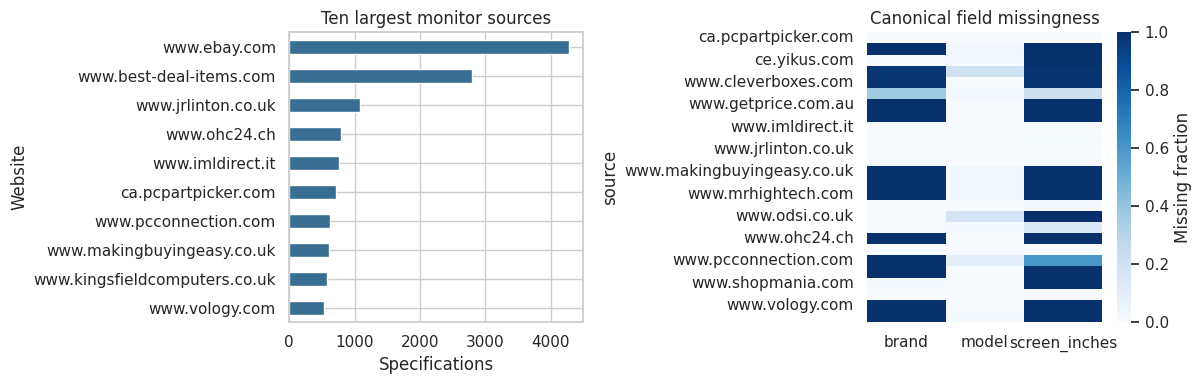

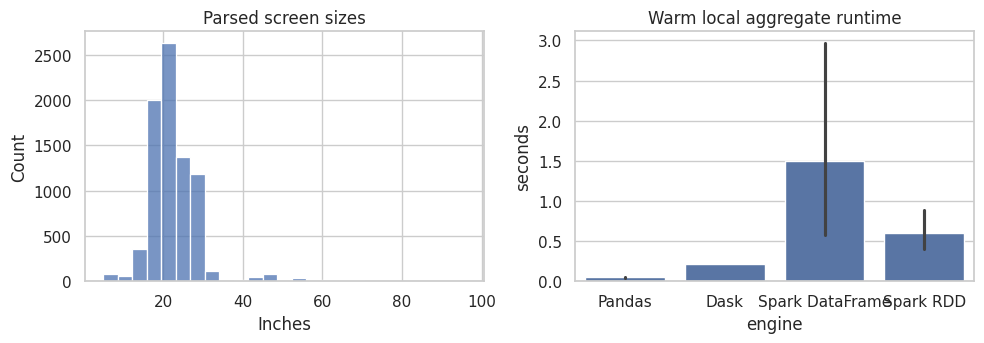

{
  "quality": {
    "records": 16662,
    "sources": 26,
    "missing_brand": 8944,
    "missing_model": 813,
    "missing_screen": 8671,
    "conflicting_records": 152
  },
  "entity_resolution": {
    "excluded_multi_entity_ids": 9,
    "labeled_records": 2264,
    "true_pairs": 9148,
    "predicted_pairs": 672,
    "tp": 667,
    "fp": 5,
    "fn": 8481,
    "precision": 0.9925595238095238,
    "recall": 0.07291211193703542,
    "f1": 0.1358452138492872
  },
  "schema_coverage": {
    "labeled_attributes": 1344,
    "mapped_attributes": 25
  },
  "status": {
    "pandas": "completed",
    "dask": "completed",
    "sql": "completed",
    "spark": "completed",
    "mongo": "completed",
    "kafka": "completed HTTP replay, Kafka, streaming, and checkpoint restart"
  },
  "versions": {
    "pandas": "2.2.3",
    "dask": "2025.2.0",
    "sqlalchemy": "2.0.39",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2"
  },
  "archive_sha256": {
    "monitor.tar.gz": "9084b8998d5afa283865dfcf8e

In [9]:
# ## 8 Visual evaluation and saved evidence
# Source volume and missingness reveal integration coverage, not market share or sales. Screen-size plots exclude missing values and retain one row per listing, so popular entities may be represented repeatedly. Timing plots describe local execution only.

sns.set_theme(style='whitegrid')
fig,axes=plt.subplots(1,2,figsize=(12,4))
clean.source.value_counts().head(10).sort_values().plot.barh(ax=axes[0],color='#376e91')
axes[0].set(xlabel='Specifications',ylabel='Website',title='Ten largest monitor sources')
missing=pd.DataFrame({'brand':clean.brand.eq(''),'model':clean.model.eq(''),'screen_inches':clean.screen_inches.isna(),'source':clean.source}).groupby('source').mean()
sns.heatmap(missing,ax=axes[1],vmin=0,vmax=1,cmap='Blues',cbar_kws={'label':'Missing fraction'})
axes[1].set_title('Canonical field missingness'); fig.tight_layout(); fig.savefig(RESULTS/'quality.png',dpi=180); plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
sns.histplot(clean.screen_inches.dropna(),bins=25,ax=axes[0]); axes[0].set_title('Parsed screen sizes'); axes[0].set_xlabel('Inches')
sns.barplot(data=timings,x='engine',y='seconds',errorbar=('pi',100),ax=axes[1]); axes[1].set_title('Warm local aggregate runtime'); fig.tight_layout(); fig.savefig(RESULTS/'analysis.png',dpi=180); plt.show()
timings.to_csv(RESULTS/'timings.csv',index=False)
evidence={'quality':quality,'entity_resolution':er,'schema_coverage':schema_summary,'status':status,'versions':versions,'archive_sha256':digest, 'spark_topology':topology, 'deduplication':dedup_summary, 'streaming':{k:v for k,v in stream_metrics.items() if k != 'progress'},
 'timing_medians':timings.groupby('engine').seconds.median().to_dict()}
(RESULTS/'evidence.json').write_text(json.dumps(evidence,indent=2),encoding='utf-8')
print(json.dumps(evidence,indent=2))

spark.stop()
